# Práctica 2. Análisis estadístico del lenguaje

En esta práctica analizo las propiedades estadísticas del corpus que armé en la Práctica 1: el
*Employment Scam Aegean Dataset*, un conjunto de ofertas de empleo en inglés etiquetadas como
legítimas o fraudulentas.

Parto de los archivos que exporté entonces, así que no hace falta repetir la limpieza:
`corpus_tokens.jsonl.gz` tiene las oraciones y los tokens de cada documento, y `corpus_limpio.csv.gz`
el texto limpio con sus metadatos.

In [1]:
import gzip, json, random, re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from wordcloud import WordCloud

RUTA = Path("corpus_procesado")
if not RUTA.exists():
    RUTA = Path.home() / "Downloads" / "corpus_procesado"
random.seed(42)

documentos = []
with gzip.open(RUTA / "corpus_tokens.jsonl.gz", "rt", encoding="utf-8") as f:
    for linea in f:
        documentos.append(json.loads(linea))

tokens_doc = [d["tokens"] for d in documentos]
contenido_doc = [d["tokens_contenido"] for d in documentos]
legitimas = [d for d in documentos if d["categoria"] == "Legítima"]
fraudulentas = [d for d in documentos if d["categoria"] == "Fraudulenta"]

# Colores y estilo comunes para todas las gráficas.
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, REJILLA = "#52514e", "#dcdcd8"
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 9.5,
                     "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.frameon": False, "legend.fontsize": 8.5})

def estilizar(ax, rejilla="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=rejilla, color=REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)

print(f"Documentos: {len(documentos):,}")
print(f"  legítimas:    {len(legitimas):,}")
print(f"  fraudulentas: {len(fraudulentas):,}")

Documentos: 14,265
  legítimas:    13,585
  fraudulentas: 680


## 1. Exploración de distribuciones léxicas

Empiezo por lo básico: cuántas palabras hay en total, cuántas distintas, y con qué frecuencia
aparece cada una.

In [2]:
todos = [t for ts in tokens_doc for t in ts]
frecuencias = Counter(todos)
n_tokens = len(todos)
vocabulario = len(frecuencias)

print(f"Tokens totales:   {n_tokens:,}")
print(f"Palabras únicas:  {vocabulario:,}")
print(f"Razón tipo/token: {vocabulario / n_tokens:.5f}")

tabla = pd.DataFrame(frecuencias.most_common(15), columns=["palabra", "frec_absoluta"])
tabla["frec_relativa_%"] = (100 * tabla["frec_absoluta"] / n_tokens).round(3)
tabla["frec_acumulada_%"] = tabla["frec_relativa_%"].cumsum().round(2)
tabla.index = range(1, 16)
tabla

Tokens totales:   5,734,803
Palabras únicas:  55,546
Razón tipo/token: 0.00969


,palabra,frec_absoluta,frec_relativa_%,frec_acumulada_%
1,and,303119,5.286,5.29
2,the,176653,3.080,8.37
3,to,172158,3.002,11.37
4,of,129014,2.250,13.62
5,a,125560,2.189,15.81
6,in,105745,1.844,17.65
7,with,78736,1.373,19.02
8,for,70080,1.222,20.25
9,we,67848,1.183,21.43
10,you,55276,0.964,22.39


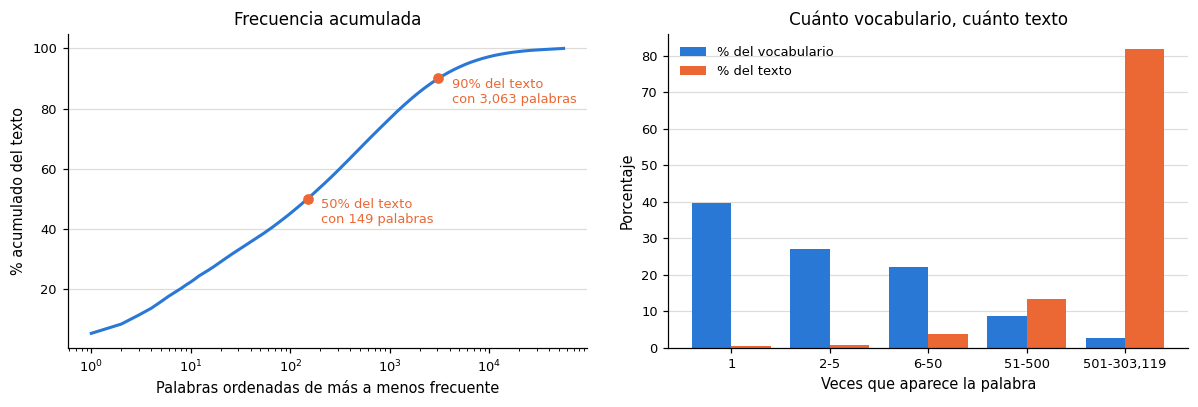

Palabras que aparecen una sola vez: 22,035 (39.7% del vocabulario, 0.38% del texto)
Palabras que aparecen 5 veces o menos: 37,017 (66.6% del vocabulario, 1.14% del texto)


In [3]:
ordenadas = np.array(sorted(frecuencias.values(), reverse=True))
acumulada = np.cumsum(ordenadas) / n_tokens

# Reparto del corpus por bandas de frecuencia: cuánto vocabulario hay en cada
# banda y cuánto texto ocupa en realidad.
bandas = [(1, 1), (2, 5), (6, 50), (51, 500), (501, ordenadas[0])]
etiquetas, pct_vocab, pct_texto = [], [], []
for minimo, maximo in bandas:
    esta_banda = (ordenadas >= minimo) & (ordenadas <= maximo)
    etiquetas.append(str(minimo) if minimo == maximo else f"{minimo}-{maximo:,}")
    pct_vocab.append(100 * esta_banda.sum() / vocabulario)
    pct_texto.append(100 * ordenadas[esta_banda].sum() / n_tokens)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

ax1.semilogx(np.arange(1, vocabulario + 1), 100 * acumulada, color=AZUL, linewidth=2)
for meta in (50, 90):
    cuantas = np.searchsorted(acumulada, meta / 100) + 1
    ax1.plot(cuantas, meta, "o", color=NARANJA, markersize=6)
    ax1.annotate(f"{meta}% del texto\ncon {cuantas:,} palabras", (cuantas, meta),
                 xytext=(9, -16), textcoords="offset points", fontsize=8.5, color=NARANJA)
ax1.set_xlabel("Palabras ordenadas de más a menos frecuente")
ax1.set_ylabel("% acumulado del texto")
ax1.set_title("Frecuencia acumulada")
estilizar(ax1)

x = np.arange(len(etiquetas))
ax2.bar(x - 0.2, pct_vocab, 0.4, color=AZUL, label="% del vocabulario")
ax2.bar(x + 0.2, pct_texto, 0.4, color=NARANJA, label="% del texto")
ax2.set_xticks(x, etiquetas)
ax2.set_xlabel("Veces que aparece la palabra")
ax2.set_ylabel("Porcentaje")
ax2.set_title("Cuánto vocabulario, cuánto texto")
ax2.legend()
estilizar(ax2)
fig.tight_layout()
plt.show()

print(f"Palabras que aparecen una sola vez: {(ordenadas == 1).sum():,} "
      f"({(ordenadas == 1).mean():.1%} del vocabulario, "
      f"{ordenadas[ordenadas == 1].sum() / n_tokens:.2%} del texto)")
print(f"Palabras que aparecen 5 veces o menos: {(ordenadas <= 5).sum():,} "
      f"({(ordenadas <= 5).mean():.1%} del vocabulario, "
      f"{ordenadas[ordenadas <= 5].sum() / n_tokens:.2%} del texto)")

El reparto de las palabras es muy desigual. Con unas pocas palabras muy comunes ya se cubre la mitad
del texto, y en cambio para llegar al 90 % hacen falta miles.

La segunda gráfica enseña las dos caras de eso. Cuatro de cada diez palabras del vocabulario
aparecen una sola vez, y aun así entre todas no llegan ni al 1 % del texto. Del otro lado pasa lo
contrario: las palabras muy frecuentes son poquísimas y se llevan casi todo. O sea que la mayor
parte del vocabulario casi no se usa, y el corpus se sostiene con un grupo pequeño de palabras.

Esto sirve para dos cosas. La primera es que puedo recortar bastante el vocabulario sin perder casi
nada de texto: si quito las palabras que aparecen menos de cinco veces, me deshago de dos tercios
del vocabulario y el texto queda casi igual. Eso hace mucho más ligera cualquier matriz de palabras
por documento. La segunda es que las palabras raras, aunque sean mayoría, aparecen tan poco que
cualquier modelo va a calcular mal su probabilidad.

In [4]:
# ¿Qué hay dentro del vocabulario? Reviso los tokens frecuentes que no parecen
# palabras normales, para ver si quedó ruido de la limpieza anterior.
def parece_palabra(t):
    return t.replace("-", "").replace("'", "").isalpha()

raros = [(t, f) for t, f in frecuencias.most_common(4000) if not parece_palabra(t)]
print(f"Entre las 4,000 palabras más frecuentes hay {len(raros)} que no parecen palabras:\n")
for t, f in raros[:12]:
    print(f"   {t:<22} {f:>6,}")

estilos_word = [(t, f) for t, f in frecuencias.items() if t.startswith("mso-")]
print(f"\nFragmentos de estilos de Word: {len(estilos_word)} distintos, "
      f"{sum(f for _, f in estilos_word):,} apariciones")

Entre las 4,000 palabras más frecuentes hay 27 que no parecen palabras:

   and/or                  3,332
   401k                    1,022
   e.g                       914
   html5                     608
   u.s                       579
   b2b                       514
   3d                        485
   i.e                       475
   css3                      363
   3rd                       282
   his/her                   265
   ui/ux                     244

Fragmentos de estilos de Word: 48 distintos, 1,650 apariciones


Casi todo lo que a primera vista parecía basura resulta ser vocabulario real del dominio: `and/or`,
`401k`, `e.g`, `html5`, `b2b`, `ui/ux`, `ba/bs`. Son abreviaturas, tecnologías y siglas de recursos
humanos, así que está bien que sigan ahí.

Lo que sí es ruido de verdad son unos fragmentos de hojas de estilo de Microsoft Word que se me
colaron en la Práctica 1. No los detecté entonces porque no son etiquetas HTML, sino texto que
alguien pegó desde Word. Son tan pocos que no cambian ningún resultado, pero conviene quitarlos en
las prácticas siguientes.

## 2. Análisis de palabras frecuentes

Aquí uso los tokens sin stopwords, porque si no la lista se llena de artículos y preposiciones.
Además comparo el top de cada categoría para ver si las ofertas fraudulentas usan otras palabras.

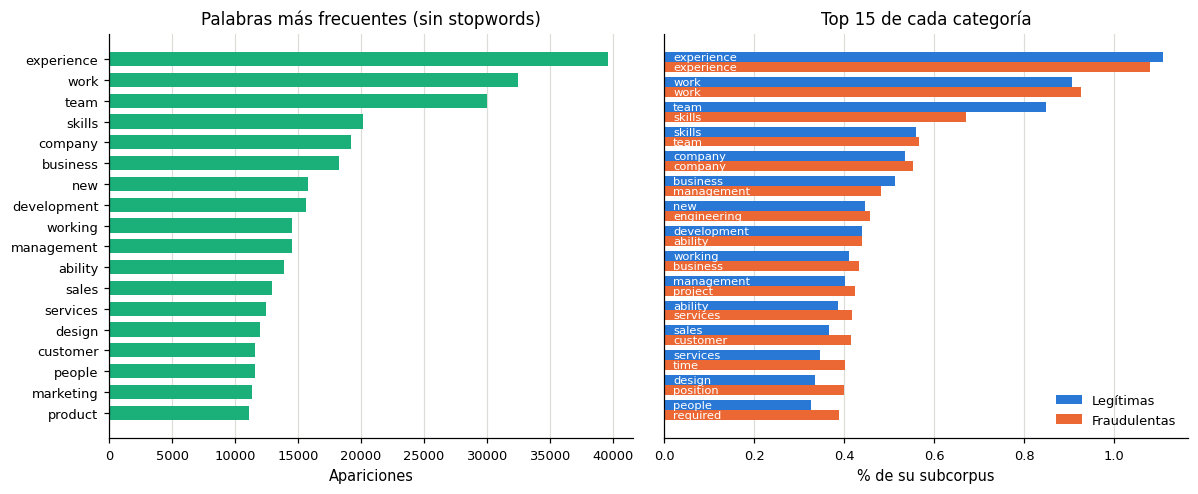

Palabras que están en los dos top 50: 36 de 50


In [5]:
contenido = [t for ts in contenido_doc for t in ts]
frec_contenido = Counter(contenido)
frec_leg = Counter(t for d in legitimas for t in d["tokens_contenido"])
frec_fra = Counter(t for d in fraudulentas for t in d["tokens_contenido"])
total_leg, total_fra = sum(frec_leg.values()), sum(frec_fra.values())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))

datos = frec_contenido.most_common(18)[::-1]
ax1.barh([p for p, _ in datos], [f for _, f in datos], color=VERDE, height=0.68)
ax1.set_xlabel("Apariciones")
ax1.set_title("Palabras más frecuentes (sin stopwords)")
estilizar(ax1, rejilla="x")

top_leg = [p for p, _ in frec_leg.most_common(15)]
top_fra = [p for p, _ in frec_fra.most_common(15)]
y = np.arange(15)[::-1]
ax2.barh(y + 0.2, [100 * frec_leg[p] / total_leg for p in top_leg], 0.4,
         color=AZUL, label="Legítimas")
ax2.barh(y - 0.2, [100 * frec_fra[p] / total_fra for p in top_fra], 0.4,
         color=NARANJA, label="Fraudulentas")
for i in range(15):
    ax2.annotate(top_leg[i], (0.02, y[i] + 0.2), fontsize=7.5, va="center", color="white")
    ax2.annotate(top_fra[i], (0.02, y[i] - 0.2), fontsize=7.5, va="center", color="white")
ax2.set_yticks([])
ax2.set_xlabel("% de su subcorpus")
ax2.set_title("Top 15 de cada categoría")
ax2.legend()
estilizar(ax2, rejilla="x")
fig.tight_layout()
plt.show()

repetidas = set(p for p, _ in frec_leg.most_common(50)) & set(p for p, _ in frec_fra.most_common(50))
print(f"Palabras que están en los dos top 50: {len(repetidas)} de 50")

Las palabras más frecuentes describen bien el tema del corpus: experiencia, trabajo, equipo,
habilidades, empresa. Es justo lo que uno esperaría de anuncios de empleo.

La comparación de la derecha es la parte interesante, porque muestra la principal limitación de este
tipo de análisis: las dos categorías tienen casi el mismo top. Comparten la mayoría de sus cincuenta
palabras más frecuentes y las primeras posiciones son casi idénticas. Visto así tiene sentido, ya
que una oferta falsa trata de parecerse a una real, o sea que lo que las diferencia no va a estar en
las palabras que más usan. Lo poco que sobresale del lado fraudulento (`engineering`, `project`)
vuelve a apuntar al sector petrolero que ya había salido en la Práctica 1, así que es un sesgo del
dataset más que una señal de fraude.

Las otras limitaciones son las de siempre. Contar palabras sueltas deja fuera el contexto, así que
no distingue significados ni detecta expresiones de varias palabras, que es lo que veo en la
siguiente sección. Y como cuento apariciones y no documentos, los textos largos pesan más.

## 3. Análisis de n-gramas

Cuento pares y tríos de palabras seguidas, en dos versiones: con todos los tokens, que es lo que
usaría un modelo de lenguaje, y sin stopwords, que deja ver las expresiones propias del tema. Los
n-gramas no cruzan de un documento a otro.

In [6]:
def contar_ngramas(secuencias, n):
    contador = Counter()
    for tokens in secuencias:
        contador.update(zip(*(tokens[i:] for i in range(n))))
    return contador

bigramas = contar_ngramas(tokens_doc, 2)
trigramas = contar_ngramas(tokens_doc, 3)
bigramas_cont = contar_ngramas(contenido_doc, 2)
trigramas_cont = contar_ngramas(contenido_doc, 3)

resumen = pd.DataFrame([
    ("Palabras sueltas", n_tokens, vocabulario,
     100 * np.mean([f == 1 for f in frecuencias.values()])),
    ("Bigramas", sum(bigramas.values()), len(bigramas),
     100 * np.mean([f == 1 for f in bigramas.values()])),
    ("Trigramas", sum(trigramas.values()), len(trigramas),
     100 * np.mean([f == 1 for f in trigramas.values()])),
], columns=["", "apariciones", "distintos", "% que aparece 1 sola vez"])
resumen["% que aparece 1 sola vez"] = resumen["% que aparece 1 sola vez"].round(1)
print(resumen.to_string(index=False))

print("\nBigramas más comunes:")
for k, f in bigramas.most_common(6):
    print(f"   {' '.join(k):<20} {f:>7,}")
print("\nTrigramas más comunes:")
for k, f in trigramas.most_common(6):
    print(f"   {' '.join(k):<20} {f:>7,}")

                  apariciones  distintos  % que aparece 1 sola vez
Palabras sueltas      5734803      55546                      39.7
        Bigramas      5720538     774402                      54.1
       Trigramas      5706273    1880282                      65.9

Bigramas más comunes:
   of the                20,029
   in the                17,670
   we are                13,809
   ability to            13,159
   is a                  11,942
   in a                  11,028

Trigramas más comunes:
   as well as             4,108
   you will be            3,835
   are looking for        3,782
   we are looking         3,664
   the ability to         3,338
   be able to             3,105


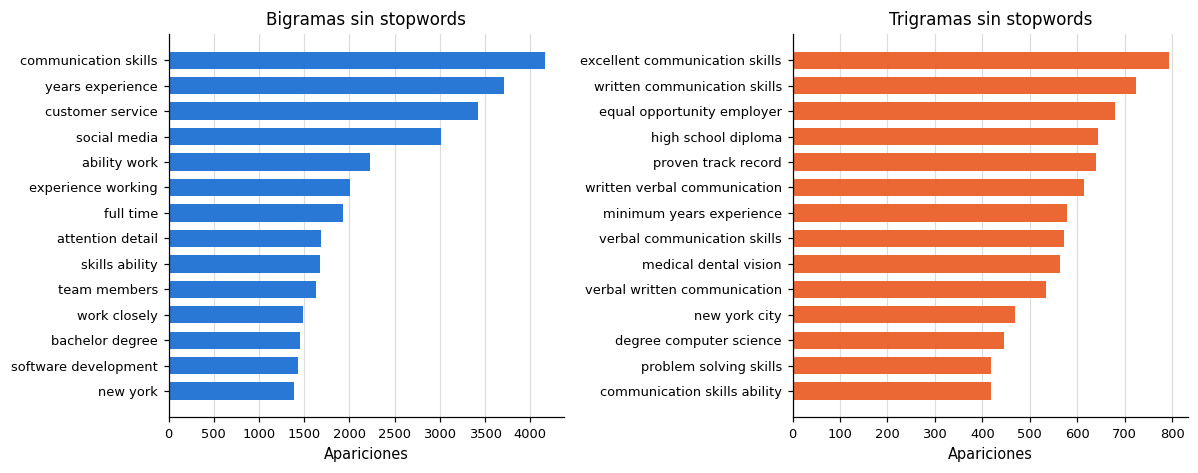

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, datos, color, titulo in [
        (ax1, bigramas_cont.most_common(14)[::-1], AZUL, "Bigramas sin stopwords"),
        (ax2, trigramas_cont.most_common(14)[::-1], NARANJA, "Trigramas sin stopwords")]:
    ax.barh([" ".join(k) for k, _ in datos], [f for _, f in datos], color=color, height=0.68)
    ax.set_xlabel("Apariciones")
    ax.set_title(titulo)
    estilizar(ax, rejilla="x")
fig.tight_layout()
plt.show()

Con todos los tokens, los n-gramas más comunes son puras secuencias gramaticales: `of the`,
`we are`, `as well as`. No dicen nada del tema, pero son exactamente lo que un modelo de lenguaje
tiene que aprender, porque son las combinaciones que arman las frases en inglés. Entre ellas se cuela
`ability to`, que de tanto repetirse ya funciona como una muletilla del género.

Al quitar las stopwords salen las frases hechas del oficio, y los trigramas las recuperan completas:
`excellent communication skills`, `equal opportunity employer`, `high school diploma`, `medical
dental vision`. Que estas frases se repitan cientos de veces dice algo del corpus: los anuncios de
empleo se escriben ensamblando bloques ya conocidos más que redactando desde cero.

La tabla muestra el problema principal de trabajar con n-gramas. Al pasar de palabras sueltas a
trigramas, la cantidad de secuencias distintas se dispara y el porcentaje de las que aparecen una
sola vez sube muchísimo. Esto se llama dispersión: la mayoría de las combinaciones posibles nunca
llega a aparecer, y por eso un modelo de trigramas sin suavizado le daría probabilidad cero a casi
cualquier frase nueva.

## 4. Patrones estadísticos del lenguaje

### 4.1 Ley de Zipf y riqueza de vocabulario por categoría

En la Práctica 1 me quedó una duda. La razón tipo/token de las ofertas fraudulentas salía mucho más
alta que la de las legítimas, lo que parecía indicar que usaban vocabulario más variado. El problema
es que esa medida baja sola conforme el texto crece, porque mientras más largo es un texto más se
repiten las palabras que ya salieron. Como un subcorpus es mucho más grande que el otro, compararlos
directamente no sirve. La forma de arreglarlo es tomar muestras del mismo tamaño de los dos y
comparar ahí.

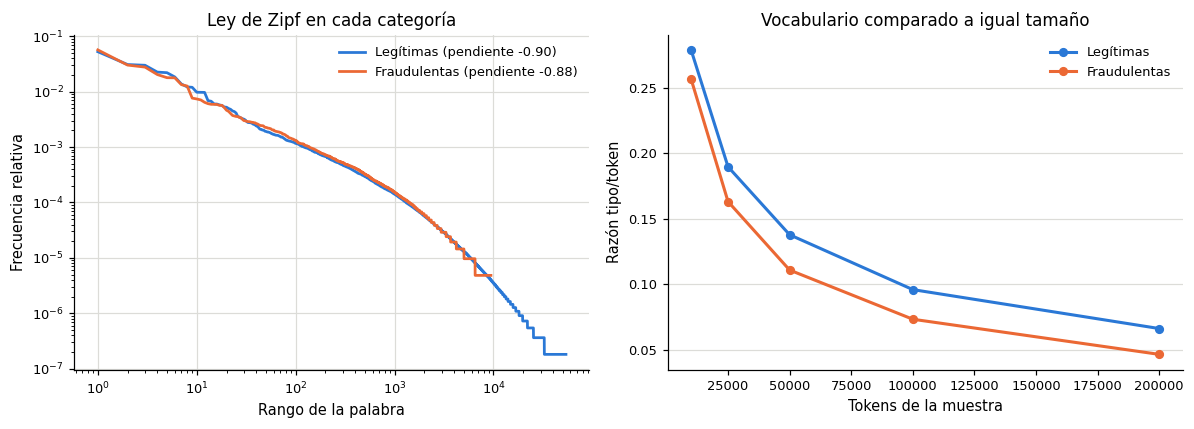

In [8]:
tokens_leg = [t for d in legitimas for t in d["tokens"]]
tokens_fra = [t for d in fraudulentas for t in d["tokens"]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

for tokens, color, nombre in [(tokens_leg, AZUL, "Legítimas"),
                              (tokens_fra, NARANJA, "Fraudulentas")]:
    f = np.array(sorted(Counter(tokens).values(), reverse=True))
    rangos = np.arange(1, len(f) + 1)
    pendiente = np.polyfit(np.log10(rangos[:1000]), np.log10(f[:1000]), 1)[0]
    ax1.loglog(rangos, f / f.sum(), color=color, linewidth=1.8,
               label=f"{nombre} (pendiente {pendiente:.2f})")
ax1.set_xlabel("Rango de la palabra")
ax1.set_ylabel("Frecuencia relativa")
ax1.set_title("Ley de Zipf en cada categoría")
ax1.legend()
estilizar(ax1, rejilla="both")

# Misma cantidad de tokens en los dos casos, promediando varias muestras.
tamanos = [10000, 25000, 50000, 100000, 200000]
for tokens, color, nombre in [(tokens_leg, AZUL, "Legítimas"),
                              (tokens_fra, NARANJA, "Fraudulentas")]:
    promedios = []
    for n in tamanos:
        pruebas = [len(set(random.sample(tokens, n))) / n for _ in range(5)]
        promedios.append(sum(pruebas) / len(pruebas))
    ax2.plot(tamanos, promedios, "o-", color=color, linewidth=2, markersize=5, label=nombre)
ax2.set_xlabel("Tokens de la muestra")
ax2.set_ylabel("Razón tipo/token")
ax2.set_title("Vocabulario comparado a igual tamaño")
ax2.legend()
estilizar(ax2)
fig.tight_layout()
plt.show()

Las dos curvas de Zipf quedan casi encimadas y sus pendientes son casi iguales. Las dos categorías
siguen la misma ley, así que la forma en que se reparten las palabras no distingue una oferta falsa
de una real.

La segunda gráfica corrige lo que pensaba en la Práctica 1, y de hecho lo da vuelta. Cuando comparo
muestras del mismo tamaño, las ofertas legítimas tienen más variedad de vocabulario que las
fraudulentas, y pasa en todos los tamaños que probé. La razón tipo/token sin corregir decía lo
contrario nada más por el efecto del tamaño. El resultado corregido encaja con lo demás que ya sabía
de las fraudulentas: son más cortas, más repetitivas y se concentran en menos sectores.

### 4.2 Cambios en el lenguaje a lo largo del documento

Los anuncios suelen seguir un orden parecido: primero la empresa se presenta, después describe el
puesto y al final habla de requisitos y prestaciones. Para ver si eso se nota en las palabras, parto
cada documento en cinco tramos según la posición de sus oraciones y comparo la frecuencia de cada
palabra dentro del tramo con la que tiene en todo el corpus.

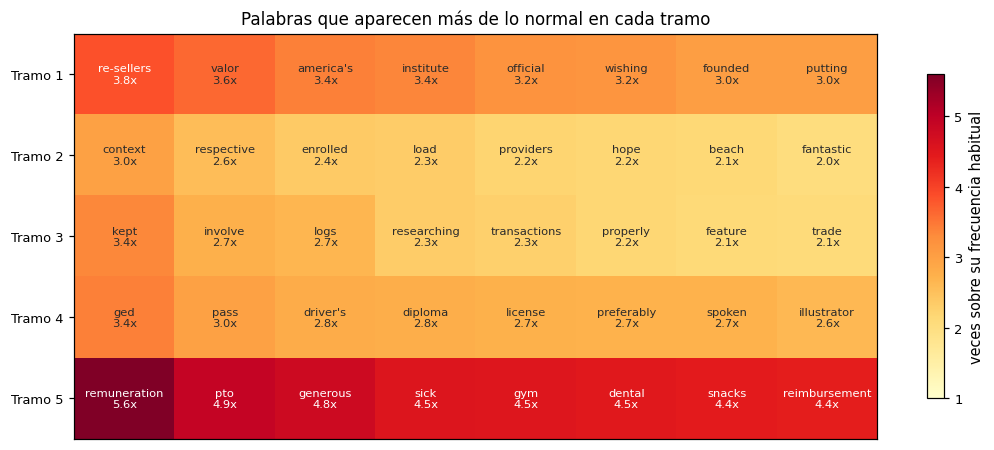

Palabras por tramo: ['918,260', '800,921', '705,586', '619,222', '557,776']


In [9]:
TRAMOS = 5
frec_tramo = [Counter() for _ in range(TRAMOS)]
docs_tramo = [Counter() for _ in range(TRAMOS)]
total_tramo = [0] * TRAMOS
PALABRA = re.compile(r"[a-z][a-z'\-]{2,}")
STOPWORDS = set(pd.read_csv(RUTA / "vocabulario.csv")
                .query("es_stopword")["palabra"].astype(str))

for d in documentos:
    oraciones = d["oraciones"]
    if len(oraciones) < TRAMOS:
        continue
    vistas = [set() for _ in range(TRAMOS)]
    for i, oracion in enumerate(oraciones):
        tramo = min(int(TRAMOS * i / len(oraciones)), TRAMOS - 1)
        palabras = [w for w in PALABRA.findall(oracion.lower()) if w not in STOPWORDS]
        frec_tramo[tramo].update(palabras)
        total_tramo[tramo] += len(palabras)
        vistas[tramo].update(palabras)
    for tramo in range(TRAMOS):
        docs_tramo[tramo].update(vistas[tramo])

frec_global = Counter()
for contador in frec_tramo:
    frec_global.update(contador)
total_global = sum(total_tramo)

# Por cada tramo, las palabras que aparecen muchas más veces de lo normal.
destacadas = []
for tramo in range(TRAMOS):
    razones = {}
    for palabra in frec_tramo[tramo]:
        if frec_global[palabra] >= 300 and docs_tramo[tramo][palabra] >= 100:
            en_tramo = frec_tramo[tramo][palabra] / total_tramo[tramo]
            en_corpus = frec_global[palabra] / total_global
            razones[palabra] = en_tramo / en_corpus
    destacadas.append(sorted(razones.items(), key=lambda x: -x[1])[:8])

matriz = np.array([[valor for _, valor in tramo] for tramo in destacadas])

fig, ax = plt.subplots(figsize=(10, 4.2))
imagen = ax.imshow(matriz, cmap="YlOrRd", aspect="auto", vmin=1)
for i in range(TRAMOS):
    for j in range(8):
        palabra, valor = destacadas[i][j]
        ax.text(j, i, f"{palabra}\n{valor:.1f}x", ha="center", va="center", fontsize=7.5,
                color="white" if valor > matriz.max() * 0.65 else "#2b2b2b")
ax.set_yticks(range(TRAMOS), [f"Tramo {i+1}" for i in range(TRAMOS)])
ax.set_xticks([])
ax.set_title("Palabras que aparecen más de lo normal en cada tramo")
fig.colorbar(imagen, ax=ax, label="veces sobre su frecuencia habitual", shrink=0.8)
fig.tight_layout()
plt.show()

print("Palabras por tramo:", [f"{n:,}" for n in total_tramo])

El lenguaje sí cambia de manera ordenada a lo largo del anuncio, y los extremos son los más claros.
En el primer tramo aparecen las palabras con las que la empresa se presenta (`founded`, `institute`,
`official`). En el cuarto están los requisitos y los títulos que piden (`ged`, `diploma`, `license`,
`driver's`). Y el quinto es el más marcado de todos: es puro vocabulario de prestaciones
(`remuneration`, `pto`, `dental`, `gym`, `snacks`), con palabras que ahí aparecen varias veces más
de lo normal.

Los tramos de en medio son más difusos y tienen palabras de tareas y procesos, que es justo donde se
describe el puesto. En conjunto el orden es el mismo con el que armé el documento en la Práctica 1:
perfil de la empresa, descripción, responsabilidades, requisitos y prestaciones. O sea que saber en
qué parte del anuncio está una palabra da información, y vale la pena guardar ese dato para las
prácticas de sintaxis y semántica.

También se nota que hay menos texto conforme avanza el anuncio: cada tramo aporta menos palabras que
el anterior, porque el final son sobre todo listas de viñetas.

## 5. Visualización comparativa del vocabulario

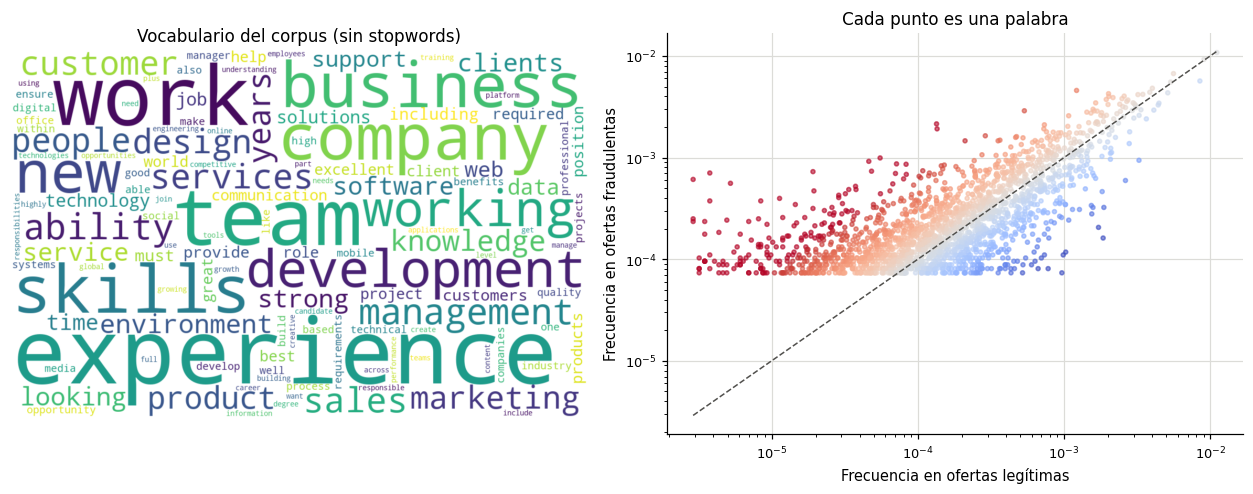

Las que más se despegan hacia las fraudulentas:
    palabra  veces_mas_en_fraudulentas
discoveries                      209.8
        hse                      186.6
    refined                      106.7
       diem                       99.2
       cuts                       85.9
  appointed                       80.9
      wheel                       67.4
compression                       50.5

Palabras comparadas: 2,120
Difieren menos del doble entre categorías: 60%


In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6))

nube = WordCloud(width=1100, height=700, background_color="white", colormap="viridis",
                 max_words=120, random_state=42).generate_from_frequencies(frec_contenido)
ax1.imshow(nube, interpolation="bilinear")
ax1.axis("off")
ax1.set_title("Vocabulario del corpus (sin stopwords)")

# Pido un mínimo de apariciones en las dos categorías: si una palabra sale muy
# pocas veces en el subcorpus fraudulento, su frecuencia no es comparable.
comunes = [p for p in set(frec_leg) & set(frec_fra)
           if frec_leg[p] >= 10 and frec_fra[p] >= 10]
x = np.array([frec_leg[p] / total_leg for p in comunes])
y = np.array([frec_fra[p] / total_fra for p in comunes])
veces = y / x

ax2.scatter(x, y, s=7, c=np.log2(veces), cmap="coolwarm", vmin=-3, vmax=3, alpha=0.6)
extremos = [min(x.min(), y.min()), max(x.max(), y.max())]
ax2.plot(extremos, extremos, color=GRIS, linewidth=1, linestyle="--")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("Frecuencia en ofertas legítimas")
ax2.set_ylabel("Frecuencia en ofertas fraudulentas")
ax2.set_title("Cada punto es una palabra")
estilizar(ax2, rejilla="both")
fig.tight_layout()
plt.show()

diferencias = pd.DataFrame({"palabra": comunes, "veces_mas_en_fraudulentas": veces.round(1)})
print("Las que más se despegan hacia las fraudulentas:")
print(diferencias.nlargest(8, "veces_mas_en_fraudulentas").to_string(index=False))
print(f"\nPalabras comparadas: {len(comunes):,}")
print(f"Difieren menos del doble entre categorías: {np.mean(abs(np.log2(veces)) < 1):.0%}")

La nube repite lo que ya decían las listas de frecuencia: el corpus gira alrededor de experiencia,
trabajo, equipo y habilidades. Está bien para dar un panorama, pero no sirve para medir, porque
comparar tamaños de letra a ojo es poco preciso.

La gráfica de puntos dice más. Cada punto es una palabra, y su posición compara qué tan seguido
aparece en cada categoría; la diagonal marca el empate. La nube de puntos sigue la diagonal y la
mayoría de las palabras no difiere ni al doble de una categoría a otra, así que el vocabulario de
fondo es el mismo. Hay bastante dispersión alrededor de la diagonal, lo cual es normal porque el
subcorpus fraudulento es chico y cada palabra se mide con más error.

Las pocas palabras que se despegan de verdad vuelven a ser del sector petrolero, que es a lo mismo
que había llegado por otros caminos en la sección 2 y en la Práctica 1.

Juntando todo, las secciones anteriores apuntan a lo mismo. Las ofertas fraudulentas no tienen un
vocabulario propio ni organizan el lenguaje de otra forma: comparten la ley de Zipf, las palabras
frecuentes y las frases hechas del género. Se diferencian por lo largas que son, por lo que dejan
fuera y por el sector que imitan. Para la práctica que sigue, eso quiere decir que la señal útil hay
que buscarla en la gramática y en cómo está escrito el anuncio, no en la lista de palabras.

Por último guardo las tablas de n-gramas, para no tener que volver a calcularlas en las prácticas
siguientes.

In [11]:
for nombre, contador in [("bigramas", bigramas), ("trigramas", trigramas)]:
    tabla_ngramas = pd.DataFrame(
        [(" ".join(k), f) for k, f in contador.items() if f >= 5],
        columns=["ngrama", "frecuencia"]).sort_values("frecuencia", ascending=False)
    tabla_ngramas.to_csv(RUTA / f"{nombre}.csv.gz", index=False, compression="gzip")
    print(f"{nombre}.csv.gz: {len(tabla_ngramas):,} filas")

bigramas.csv.gz: 144,195 filas


trigramas.csv.gz: 192,791 filas
